In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install mediapipe==0.10.13 -q
print('All dependencies installed!')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.6/35.6 MB 46.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.2/295.2 kB 14.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opentelemetry-proto 1.38.0 requires protobuf<7.0,>=5.0, but you have protobuf 4.25.9 which is incompatible.
grain 0.2.16 requires protobuf>=5.28.3, but you have protobuf 4.25.9 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 4.25.9 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 4.25.9 which is incompatible.
All dependencies installed!


In [3]:
import numpy as np
import os
import joblib
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from collections import deque

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense

import matplotlib.pyplot as plt
import seaborn as sns

print('All imports successful!')

All imports successful!


In [4]:
data_path = '/content/drive/Shareddrives/PRJ303_Dataset/dataset'

if os.path.exists(data_path):
    print('Dataset folder found!')
    print('Contents:', os.listdir(data_path))
else:
    print('ERROR: Path not found!')
    print('Available drives:')
    print(os.listdir('/content/drive/'))

Dataset folder found!
Contents: ['erase', 'screenshot', 'clear', 'draw', 'color', 'scroll', 'cursor']


In [5]:
X = []
y = []

for label in os.listdir(data_path):
    class_path = os.path.join(data_path, label)

    if os.path.isdir(class_path):
        for file in os.listdir(class_path):
            if file.endswith('.npy'):
                file_path = os.path.join(class_path, file)
                data = np.load(file_path)
                X.append(data)
                y.append(label)

if len(X) == 0:
    raise ValueError('No .npy files found! Check your dataset folder structure.')

X = np.array(X)
y = np.array(y)

print('Dataset Shape:', X.shape)
print('Labels found:', np.unique(y))
print('Total samples:', len(y))

Dataset Shape: (700, 50, 126)
Labels found: ['clear' 'color' 'cursor' 'draw' 'erase' 'screenshot' 'scroll']
Total samples: 700


In [6]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y)

print('Classes:', le.classes_)

Classes: ['clear' 'color' 'cursor' 'draw' 'erase' 'screenshot' 'scroll']


In [9]:
from sklearn.preprocessing import StandardScaler
import numpy as np

samples, timesteps, features = X.shape

X_reshaped = X.reshape(-1, features)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_reshaped)

X_scaled = X_scaled.reshape(samples, timesteps, features)

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print('Train size:', X_train.shape)
print('Test size:', X_test.shape)

Train size: (560, 50, 126)
Test size: (140, 50, 126)


In [14]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense

model = Sequential()

model.add(GRU(64, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(32, activation='relu'))
model.add(Dense(len(set(y_encoded)), activation='softmax'))

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=50,
    batch_size=32,
    verbose=1
)

print("\nTraining completed")

Epoch 1/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.5482 - loss: 1.3588 - val_accuracy: 0.6214 - val_loss: 1.0705
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.7393 - loss: 0.8662 - val_accuracy: 0.8214 - val_loss: 0.7527
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.8500 - loss: 0.5952 - val_accuracy: 0.9143 - val_loss: 0.5110
Epoch 4/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.9179 - loss: 0.3917 - val_accuracy: 0.9500 - val_loss: 0.3115
Epoch 5/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9643 - loss: 0.2371 - val_accuracy: 0.9714 - val_loss: 0.1753
Epoch 6/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9714 - loss: 0.1421 - val_accuracy: 0.9857 - val_loss: 0.0972
Epoch 7/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9804 - loss: 0.0974 - val_accuracy: 0.9857 - val_loss: 0.0727
Epoch 8/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9911 - loss: 0.0608 - val_accuracy: 0.9929 - 

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 307ms/step
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

       clear       1.00      1.00      1.00        20
       color       1.00      1.00      1.00        20
      cursor       1.00      1.00      1.00        20
        draw       1.00      1.00      1.00        20
       erase       1.00      1.00      1.00        20
  screenshot       1.00      1.00      1.00        20
      scroll       1.00      1.00      1.00        20

    accuracy                           1.00       140
   macro avg       1.00      1.00      1.00       140
weighted avg       1.00      1.00      1.00       140



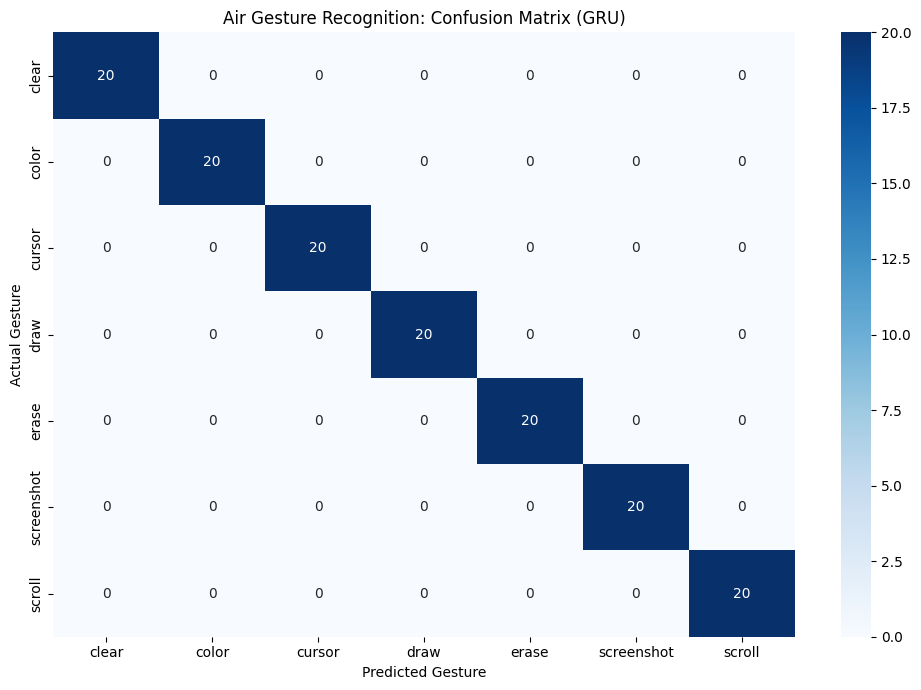

In [15]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

print('Accuracy:', accuracy_score(y_test, y_pred))
print('\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=le.classes_))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)

plt.title('Air Gesture Recognition: Confusion Matrix (GRU)')
plt.xlabel('Predicted Gesture')
plt.ylabel('Actual Gesture')
plt.tight_layout()
plt.show()

In [17]:
import joblib

save_path = '/content/drive/Shareddrives/PRJ303_Dataset/'

model.save(save_path + 'gesture_model_gru.h5')

joblib.dump(scaler, save_path + 'scaler_gru.pkl')
joblib.dump(le, save_path + 'label_encoder.pkl')

print('GRU Model saved successfully to Shared Drive!')

GRU Model saved successfully to Shared Drive!


In [18]:
from google.colab import drive
from google.colab.patches import cv2_imshow

from IPython.display import display, Javascript, Image
from base64 import b64decode, b64encode

import cv2
import numpy as np
import mediapipe as mp
import joblib
from collections import deque
from PIL import Image
import io

print('Imports done!')

Imports done!


In [21]:
import joblib
from tensorflow.keras.models import load_model

save_path = '/content/drive/Shareddrives/PRJ303_Dataset/'

model = load_model(save_path + 'gesture_model_gru.h5')

scaler_rt = joblib.load(save_path + 'scaler_gru.pkl')
le_rt = joblib.load(save_path + 'label_encoder.pkl')

print('GRU Model loaded!')
print('Gesture classes:', le_rt.classes_)

GRU Model loaded!
Gesture classes: ['clear' 'color' 'cursor' 'draw' 'erase' 'screenshot' 'scroll']


In [22]:
from IPython.display import display, Javascript
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
    async function takePhoto(quality) {
        const div = document.createElement('div');

        const capture = document.createElement('button');
        capture.textContent = 'Capture Gesture';
        capture.style.fontSize = '18px';
        capture.style.padding = '10px 20px';
        capture.style.margin = '10px';

        div.appendChild(capture);

        const video = document.createElement('video');
        video.style.display = 'block';

        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        document.body.appendChild(div);
        div.appendChild(video);

        video.srcObject = stream;
        await video.play();

        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

        await new Promise((resolve) => capture.onclick = resolve);

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getVideoTracks()[0].stop();
        div.remove();

        return canvas.toDataURL('image/jpeg', quality);
    }
    ''')

    display(js)

    from google.colab.output import eval_js
    data = eval_js(f'takePhoto({quality})')

    binary = b64decode(data.split(',')[1])

    with open(filename, 'wb') as f:
        f.write(binary)

    return filename

print('Camera function ready!')

Camera function ready!


In [23]:
import mediapipe as mp
import numpy as np
from collections import deque

mp_hands = mp.solutions.hands
mp_draw  = mp.solutions.drawing_utils

gesture_buffer = deque(maxlen=10)

def extract_features_two_hands(results):
    left_hand  = np.zeros(63)
    right_hand = np.zeros(63)

    if results.multi_hand_landmarks and results.multi_handedness:
        for hand_landmarks, handedness in zip(
            results.multi_hand_landmarks, results.multi_handedness
        ):
            hand_features = []

            for lm in hand_landmarks.landmark:
                hand_features.extend([lm.x, lm.y, lm.z])

            if handedness.classification[0].label == 'Left':
                right_hand = np.array(hand_features)
            else:
                left_hand = np.array(hand_features)

    return np.concatenate([left_hand, right_hand]).reshape(1, -1)

print('Feature extractor ready!')

Feature extractor ready!


<IPython.core.display.Javascript object>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


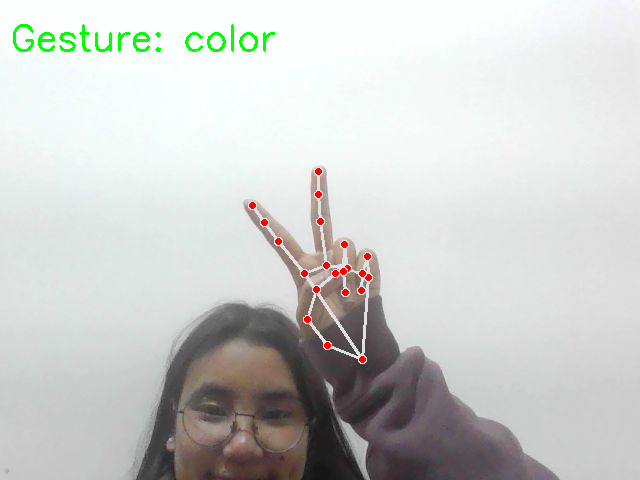


Predicted Gesture: color


In [26]:
gesture_buffer.clear()

filename = take_photo('gesture_capture.jpg')

frame = cv2.imread(filename)
frame = cv2.flip(frame, 1)
rgb   = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

with mp_hands.Hands(
    max_num_hands=2,
    min_detection_confidence=0.7,
    min_tracking_confidence=0.7
) as hands:

    result = hands.process(rgb)

    if result.multi_hand_landmarks:

        for hand_landmarks in result.multi_hand_landmarks:
            mp_draw.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

        features = extract_features_two_hands(result)

        features = features.reshape(1, 1, features.shape[1])

        features_scaled = scaler_rt.transform(features.reshape(1, -1))
        features_scaled = features_scaled.reshape(1, 1, 126)

        pred_probs = model.predict(features_scaled)
        pred_class = np.argmax(pred_probs, axis=1)[0]

        gesture_name = le_rt.inverse_transform([pred_class])[0]

    else:
        gesture_name = 'No Hand Detected'

cv2.putText(frame, f'Gesture: {gesture_name}',
            (10, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 255, 0), 2)

cv2_imshow(frame)

print(f'\nPredicted Gesture: {gesture_name}')